29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1: Loss=0.1051, Accuracy=0.1537
Epoch 2: Loss=0.0970, Accuracy=0.0883
Epoch 3: Loss=0.0925, Accuracy=0.1597
Epoch 4: Loss=0.0875, Accuracy=0.1233
Epoch 5: Loss=0.0809, Accuracy=0.0700
Epoch 6: Loss=0.0766, Accuracy=0.1230
Epoch 7: Loss=0.0750, Accuracy=0.0920
Epoch 8: Loss=0.0737, Accuracy=0.1123
Epoch 9: Loss=0.0724, Accuracy=0.1030
Epoch 10: Loss=0.0710, Accuracy=0.1133

Final Accuracy: 0.11333333333333333

Classification Report:
               precision    recall  f1-score   support

           0       0.01      0.01      0.01       300
           1       0.29      0.31      0.30       300
           2       0.01      0.00      0.00       300
           3       0.14      0.14      0.14       300
           4       0.08      0.03      0.04       300
           5       0.05      0.05      0.05 

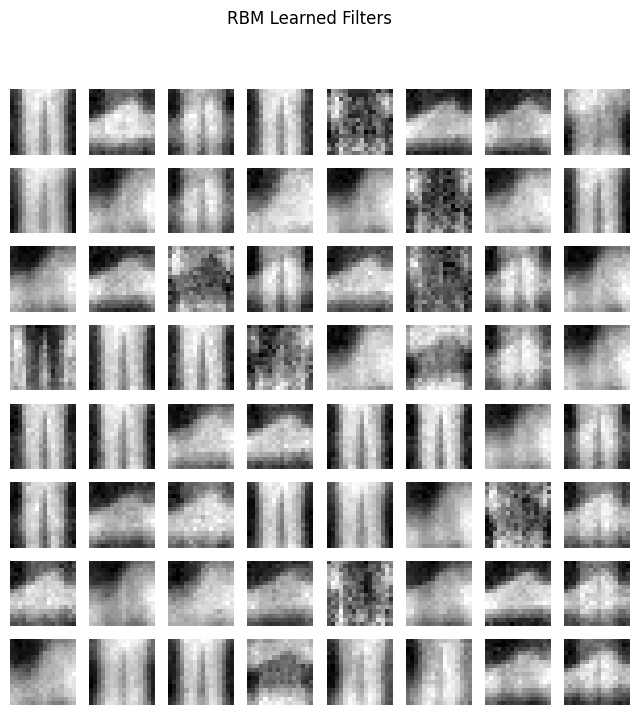

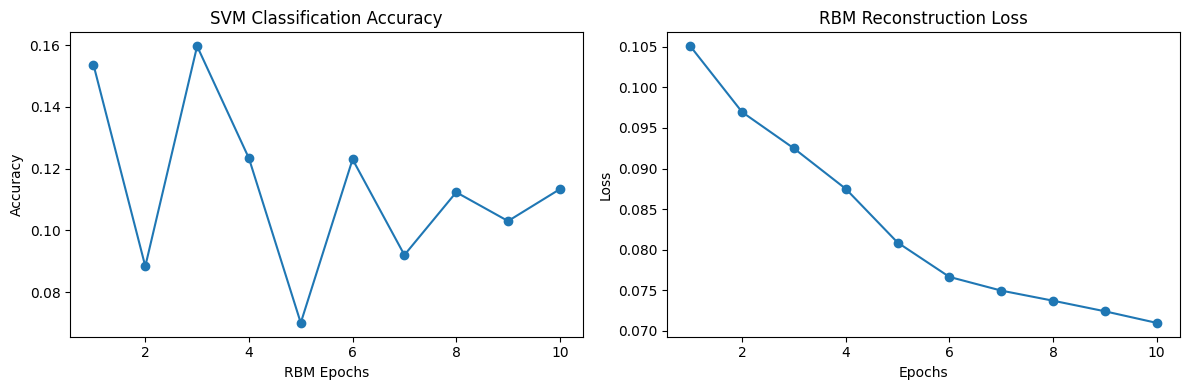

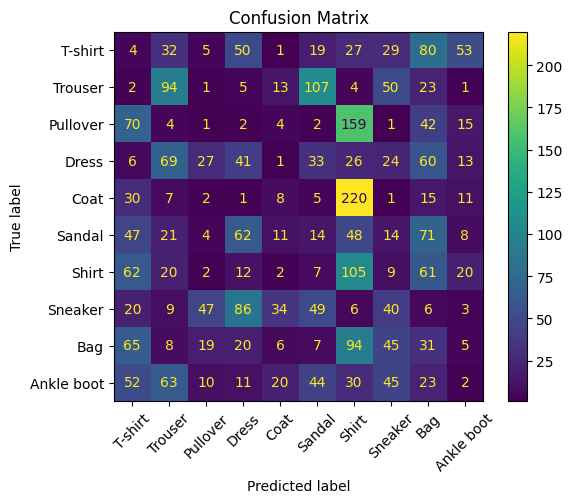

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

# Load Fashion-MNIST
(x, y), (xt, yt) = tf.keras.datasets.fashion_mnist.load_data()

# Extract 16x16 patches
x = x[:, 6:22, 6:22] / 255.0
xt = xt[:, 6:22, 6:22] / 255.0

X = x.reshape(-1, 256)
Xt = xt.reshape(-1, 256)

X_train, _, y_train, _ = train_test_split(
    X, y, train_size=12000, random_state=42, stratify=y)

X_test, _, y_test, _ = train_test_split(
    Xt, yt, train_size=3000, random_state=42, stratify=yt)

# RBM
class RBM:
    def __init__(self, nv, nh):
        self.W = np.random.normal(0, 0.01, (nv, nh))
        self.vb = np.zeros(nv)
        self.hb = np.zeros(nh)

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-np.clip(x, -30, 30)))

    def transform(self, X):
        return self.sigmoid(X @ self.W + self.hb)

    def train(self, X, epochs=10, lr=0.01, batch=128):
        losses = []
        for epoch in range(epochs):
            np.random.shuffle(X)
            for i in range(0, len(X), batch):
                v0 = X[i:i+batch]
                ph = self.transform(v0)
                h = (np.random.rand(*ph.shape) < ph).astype(float)
                pv = self.sigmoid(h @ self.W.T + self.vb)
                nh = self.sigmoid(pv @ self.W + self.hb)

                self.W += lr * (v0.T @ ph - pv.T @ nh) / len(v0)
                self.vb += lr * np.mean(v0-pv, axis=0)
                self.hb += lr * np.mean(ph-nh, axis=0)

            recon = self.sigmoid(
                self.transform(X) @ self.W.T + self.vb)
            loss = np.mean((X-recon)**2)
            losses.append(loss)

            # SVM accuracy after each RBM epoch
            svm = LinearSVC(max_iter=2000, dual="auto")
            svm.fit(self.transform(X), y_train)
            acc = accuracy_score(y_test, svm.predict(self.transform(X_test)))
            accuracies.append(acc)

            print(f"Epoch {epoch+1}: Loss={loss:.4f}, Accuracy={acc:.4f}")

        return losses

rbm = RBM(256, 64)
accuracies = []
losses = rbm.train(X_train, epochs=10)

# Final SVM
svm = LinearSVC(max_iter=2000, dual="auto")
svm.fit(rbm.transform(X_train), y_train)
pred = svm.predict(rbm.transform(X_test))

print("\nFinal Accuracy:", accuracy_score(y_test, pred))
print("\nClassification Report:\n",
      classification_report(y_test, pred))

# Learned filters
plt.figure(figsize=(8,8))
for i in range(64):
    plt.subplot(8,8,i+1)
    plt.imshow(rbm.W[:,i].reshape(16,16), cmap="gray")
    plt.axis("off")
plt.suptitle("RBM Learned Filters")
plt.show()

# Accuracy and loss graphs
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(range(1,11), accuracies, marker="o")
plt.title("SVM Classification Accuracy")
plt.xlabel("RBM Epochs")
plt.ylabel("Accuracy")

plt.subplot(1,2,2)
plt.plot(range(1,11), losses, marker="o")
plt.title("RBM Reconstruction Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    display_labels=["T-shirt","Trouser","Pullover","Dress","Coat",
                    "Sandal","Shirt","Sneaker","Bag","Ankle boot"],
    xticks_rotation=45
)
plt.title("Confusion Matrix")
plt.show()